# Random Forest Classification

## Objective

In this notebook, we will learn how to implement Random Forest
using Python and Scikit-learn.

We will cover:

1. Understanding the dataset
2. Training a Decision Tree
3. Training a Random Forest
4. Making predictions
5. Evaluating model performance
6. Understanding feature importance
7. Exploring hyperparameters
8. Comparing Decision Tree and Random Forest

Dataset: Iris Dataset
Problem Type: Multi-class Classification

Import Libraries (Code)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

Load Dataset (Code)

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["species"] = iris.target_names[y]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Understand the Dataset

In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Check Target Distribution

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


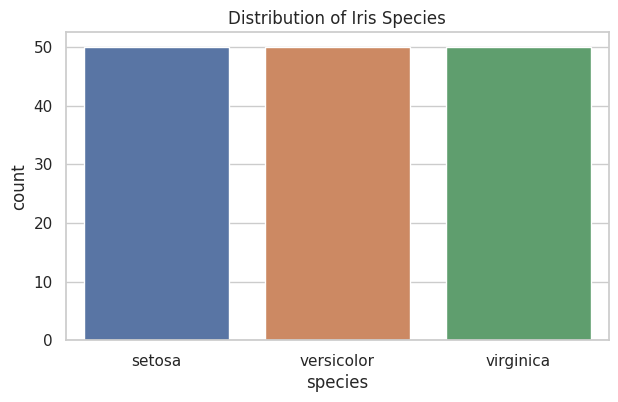

In [4]:
print(df["species"].value_counts())

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="species",
    hue="species",
    legend=False
)

plt.title("Distribution of Iris Species")
plt.show()

## Train-Test Split

We divide the dataset into two parts:

- Training data: Used to train the model.
- Testing data: Used to evaluate the model on unseen observations.

We use an 80:20 split.

The `stratify=y` parameter maintains approximately the same
class distribution in both datasets.

Train-Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


Train a Decision Tree

In [6]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(
    y_test,
    dt_predictions
)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.9333333333333333


## Building a Random Forest

Instead of training one Decision Tree, we will train
multiple Decision Trees and combine their predictions.

Important parameters:

- n_estimators: Number of trees.
- max_depth: Maximum depth of each tree.
- max_features: Number of features considered at each split.
- random_state: Controls randomness for reproducibility.

Create Random Forest Model

In [7]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    max_features="sqrt",
    random_state=42
)

Train Random Forest

In [8]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Number of Trees

In [9]:
print(
    "Number of trees in Random Forest:",
    len(rf_model.estimators_)
)

Number of trees in Random Forest: 100


Make Predictions

In [10]:
rf_predictions = rf_model.predict(X_test)

print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(rf_predictions)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 2 1 0 2 0]


Evaluate Accuracy

In [11]:
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9


Classification Report

In [12]:
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



Confusion Matrix

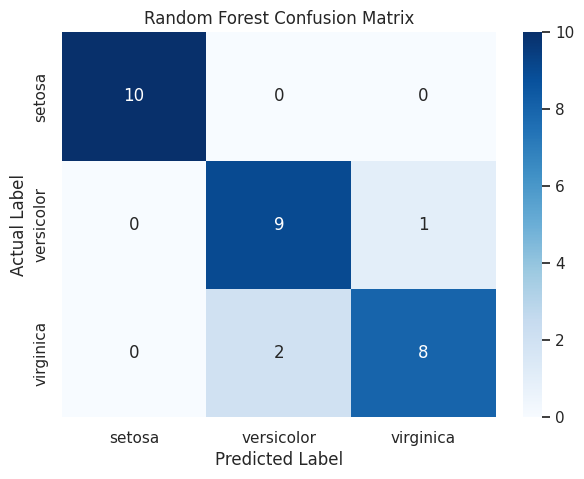

In [13]:
cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")

plt.show()

Understand Individual Tree Predictions  
This is a particularly useful cell for teaching the concept of voting.

In [17]:
# Take one observation from the test dataset

sample = X_test[0].reshape(1, -1)

print("Actual Class:", iris.target_names[y_test[0]])

# Get predictions from individual trees

individual_predictions = []

for i, tree in enumerate(rf_model.estimators_):
    prediction = tree.predict(sample)[0]
    individual_predictions.append(prediction)
    print(
        f"Tree {i+1}:",
        prediction
    )

# Final Random Forest prediction

final_prediction = rf_model.predict(sample)[0]

print("\nFinal Random Forest Prediction:")
print(final_prediction)

Actual Class: setosa
Tree 1: 0.0
Tree 2: 0.0
Tree 3: 0.0
Tree 4: 0.0
Tree 5: 0.0
Tree 6: 0.0
Tree 7: 0.0
Tree 8: 0.0
Tree 9: 0.0
Tree 10: 0.0
Tree 11: 0.0
Tree 12: 0.0
Tree 13: 0.0
Tree 14: 0.0
Tree 15: 0.0
Tree 16: 0.0
Tree 17: 0.0
Tree 18: 0.0
Tree 19: 0.0
Tree 20: 0.0
Tree 21: 0.0
Tree 22: 0.0
Tree 23: 0.0
Tree 24: 0.0
Tree 25: 0.0
Tree 26: 0.0
Tree 27: 0.0
Tree 28: 0.0
Tree 29: 0.0
Tree 30: 0.0
Tree 31: 0.0
Tree 32: 0.0
Tree 33: 0.0
Tree 34: 0.0
Tree 35: 0.0
Tree 36: 0.0
Tree 37: 0.0
Tree 38: 0.0
Tree 39: 0.0
Tree 40: 0.0
Tree 41: 0.0
Tree 42: 0.0
Tree 43: 0.0
Tree 44: 0.0
Tree 45: 0.0
Tree 46: 0.0
Tree 47: 0.0
Tree 48: 0.0
Tree 49: 0.0
Tree 50: 0.0
Tree 51: 0.0
Tree 52: 0.0
Tree 53: 0.0
Tree 54: 0.0
Tree 55: 0.0
Tree 56: 0.0
Tree 57: 0.0
Tree 58: 0.0
Tree 59: 0.0
Tree 60: 0.0
Tree 61: 0.0
Tree 62: 0.0
Tree 63: 0.0
Tree 64: 0.0
Tree 65: 0.0
Tree 66: 0.0
Tree 67: 0.0
Tree 68: 0.0
Tree 69: 0.0
Tree 70: 0.0
Tree 71: 0.0
Tree 72: 0.0
Tree 73: 0.0
Tree 74: 0.0
Tree 75: 0.0
Tree 76: 0.0


Visualize Voting

,Species,Votes
0,setosa,100


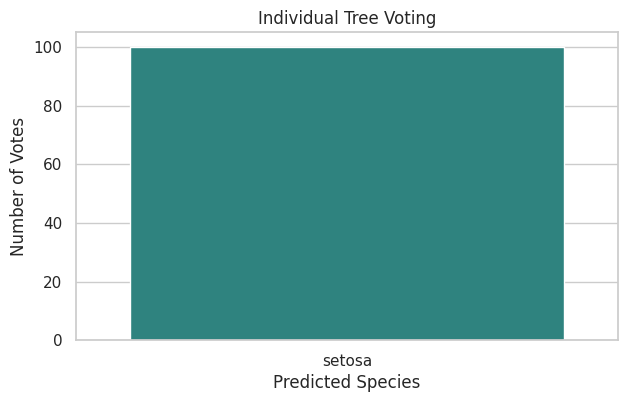

In [19]:
from collections import Counter

# Count predictions from individual trees
votes = Counter(individual_predictions)

# Create a DataFrame for visualization
vote_df = pd.DataFrame({
    "Species": list(votes.keys()),
    "Votes": list(votes.values())
})

# Convert numerical labels to species names if necessary
vote_df["Species"] = vote_df["Species"].apply(
    lambda x: iris.target_names[int(x)]
)

display(vote_df)

# Visualize voting
plt.figure(figsize=(7, 4))

sns.barplot(
    data=vote_df,
    x="Species",
    y="Votes",
    hue="Species",
    legend=False,
    palette="viridis"
)

plt.title("Individual Tree Voting")
plt.ylabel("Number of Votes")
plt.xlabel("Predicted Species")

plt.show()

## Understanding Feature Importance

Random Forest can estimate the importance of each feature.

Feature importance tells us how useful a feature was
for reducing impurity across the trees.

We will visualize the importance scores to understand
which features contributed most to the model.

Feature Importance

In [20]:
importance_df = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
3,petal width (cm),0.437185
2,petal length (cm),0.431466
0,sepal length (cm),0.116349
1,sepal width (cm),0.015000


Visualize Feature Importance

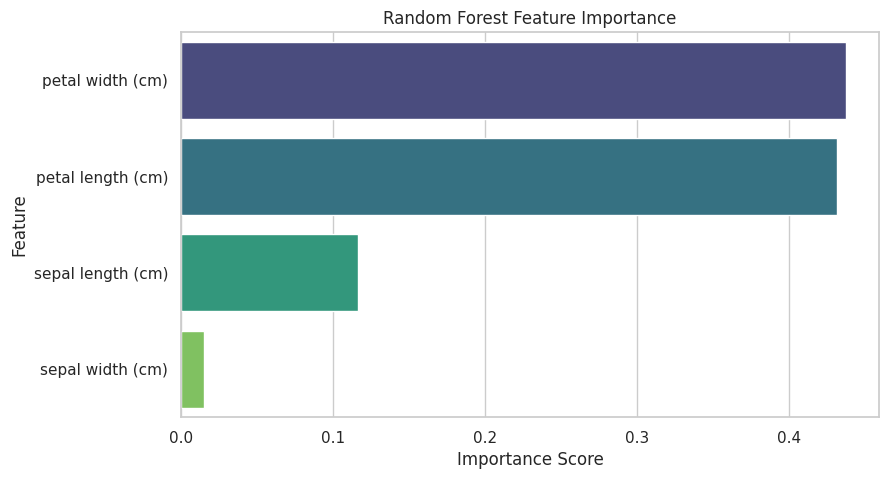

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    legend=False,
    palette="viridis"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

## Hyperparameter Experimentation

### Experiment 1: Number of Trees

Let's understand what happens when we change the number
of Decision Trees in the Random Forest.

We will experiment with:

- 1 tree
- 5 trees
- 10 trees
- 50 trees
- 100 trees
- 200 trees

Observe how the accuracy changes.

Change Number of Trees

In [22]:
tree_counts = [1, 5, 10, 50, 100, 200]

results = []

for n in tree_counts:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    results.append({
        "Number of Trees": n,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

display(results_df)

,Number of Trees,Accuracy
0,1,0.966667
1,5,0.933333
2,10,0.966667
3,50,0.900000
4,100,0.900000
5,200,0.900000


Visualize Number of Trees Experiment

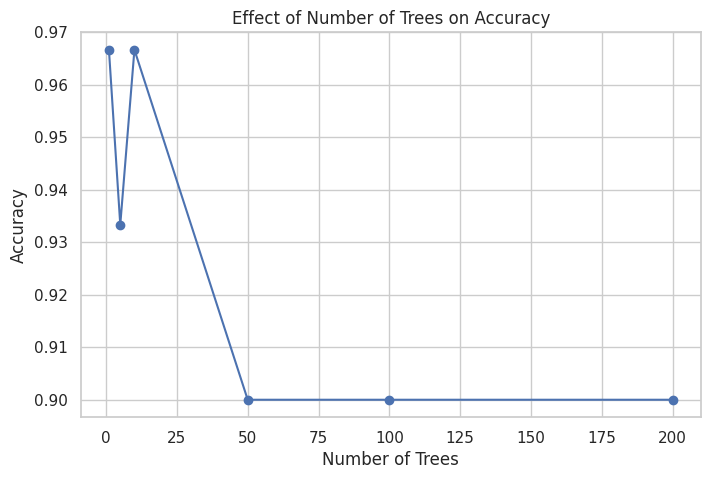

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Number of Trees"],
    results_df["Accuracy"],
    marker="o"
)

plt.xlabel("Number of Trees")
plt.ylabel("Accuracy")
plt.title("Effect of Number of Trees on Accuracy")

plt.show()

Experiment with max_depth

In [24]:
depth_values = [1, 2, 3, 4, 5, 10, None]

depth_results = []

for depth in depth_values:

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    depth_results.append({
        "Max Depth": str(depth),
        "Accuracy": accuracy
    })

depth_df = pd.DataFrame(depth_results)

display(depth_df)

,Max Depth,Accuracy
0,1,0.966667
1,2,0.900000
2,3,0.966667
3,4,0.966667
4,5,0.933333
5,10,0.900000
6,None,0.900000


Compare Decision Tree vs Random Forest

,Algorithm,Accuracy
0,Decision Tree,0.933333
1,Random Forest,0.900000


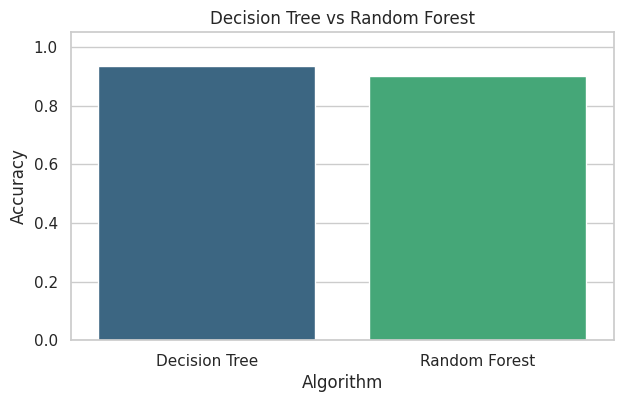

In [25]:
comparison = pd.DataFrame({
    "Algorithm": [
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        dt_accuracy,
        rf_accuracy
    ]
})

display(comparison)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Accuracy",
    hue="Algorithm",
    legend=False,
    palette="viridis"
)

plt.ylim(0, 1.05)

plt.title("Decision Tree vs Random Forest")

plt.show()

Predict for a New Flower

In [26]:
# Example new flower measurements:
# Sepal Length, Sepal Width, Petal Length, Petal Width

new_flower = np.array([
    [5.1, 3.5, 1.4, 0.2]
])

prediction = rf_model.predict(new_flower)

print("Predicted Species:")
print(iris.target_names[prediction[0]])

Predicted Species:
setosa


Predict Class Probabilities

In [27]:
probabilities = rf_model.predict_proba(new_flower)

for species, probability in zip(
    iris.target_names,
    probabilities[0]
):
    print(f"{species}: {probability:.2%}")

setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%
